# Phase 2 — Univariate Exponential Hawkes Process (MLE from scratch)
### Hawkes-Process-Driven Market Making · LOBSTER AAPL 2012-06-21 (Level 10)

In **Phase 1** we showed that executed-trade arrivals are *not* Poisson: interarrivals are
overdispersed (CV ≈ 2.6), autocorrelated (Ljung–Box rejected independence) and non-exponential
(KS rejected). The intensity clusters in bursts. This notebook fits the model that explains those
bursts — a **self-exciting Hawkes process** — entirely **from scratch** (no Hawkes library).

**Conditional intensity**

$$\lambda(t) = \mu + \alpha \sum_{t_i < t} e^{-\beta (t - t_i)}, \qquad \mu,\alpha,\beta > 0.$$

| symbol | meaning | units |
|---|---|---|
| $\mu$ | baseline (exogenous) intensity | events/s |
| $\alpha$ | jump in intensity right after each trade | events/s |
| $\beta$ | decay rate of the excitation (memory $\sim 1/\beta$) | 1/s |

Each trade gives the intensity a kick of size $\alpha$ that fades at rate $\beta$. Trades beget
trades — exactly the clustering Phase 1 found.

> This notebook mirrors the standalone `hawkes_mle.py` but is written to be *read*: every formula is
> derived in markdown immediately before the code that implements it.

---
## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy import stats

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

DATA_DIR = "../LOBSTER_SampleFile_AAPL_2012-06-21_10"
MSG_FILE = os.path.join(DATA_DIR, "AAPL_2012-06-21_34200000_57600000_message_10.csv")
PLOTS_DIR = "../plots"
os.makedirs(PLOTS_DIR, exist_ok=True)

## 1. Executed-trade timestamps

We reuse the Phase-1 recipe: keep message-file event types **4 (visible execution)** and
**5 (hidden execution)** — these are the trades.

**Why de-duplicate timestamps?** A single marketable order that sweeps several resting orders /
price levels is logged as several executions sharing one timestamp. A point process cannot have two
events at the same instant (the likelihood would be ill-defined and $\lambda(t_i)$ would double-count),
so we collapse simultaneous executions into one trade event — consistent with Phase 1.

We then **shift time to start at 0** (numerical stability) and set the observation horizon $T$ to the
last trade time.

In [2]:
cols = ["time", "event_type", "order_id", "size", "price", "direction"]
msg = pd.read_csv(MSG_FILE, header=None, names=cols)

trades = msg.loc[msg["event_type"].isin([4, 5]), "time"].to_numpy()
trades = np.unique(trades)            # sorted + de-duplicated
t = trades - trades[0]                # shift origin to 0
T = float(t[-1])                      # observation horizon (s)
N = t.size

pois_rate = N / T                     # homogeneous-Poisson MLE rate
print(f"Executed trades (de-duplicated): {N:,}")
print(f"Observation horizon T          : {T:,.1f} s  ({T/3600:.2f} h)")
print(f"Homogeneous-Poisson rate N/T   : {pois_rate:.4f} trades/s")

Executed trades (de-duplicated): 24,861
Observation horizon T          : 23,399.6 s  (6.50 h)
Homogeneous-Poisson rate N/T   : 1.0625 trades/s


## 2. The log-likelihood

For a point process with intensity $\lambda(t)$ and history $\mathcal H_t$, the log-likelihood of
events $t_1<\dots<t_N$ on $[0,T]$ is the standard expression

$$\boxed{\;\log L = \sum_{i=1}^N \log \lambda(t_i)\;-\;\int_0^T \lambda(s)\,ds\;}\tag{$\star$}$$

The first term rewards placing high intensity where trades actually occurred; the integral term (the
**compensator** $\Lambda(T)$ = expected number of events) penalises high intensity everywhere.

**Closed-form compensator.** For the exponential kernel,

$$\int_0^T \lambda(s)\,ds = \mu T + \frac{\alpha}{\beta}\sum_{i=1}^N\Big(1-e^{-\beta(T-t_i)}\Big),$$

because $\int_{t_i}^{T}\alpha e^{-\beta(s-t_i)}ds = \tfrac{\alpha}{\beta}\big(1-e^{-\beta(T-t_i)}\big)$.

### 2a. The O(N) recursion (the crucial trick)

The log-intensity term looks $O(N^2)$ because $\lambda(t_i)=\mu+\alpha\sum_{j<i}e^{-\beta(t_i-t_j)}$
sums over *all* earlier trades. Define the excitation sum

$$A_i = \sum_{j<i} e^{-\beta(t_i - t_j)}, \qquad \text{so}\quad \lambda(t_i) = \mu + \alpha A_i.$$

With $\Delta_i = t_i - t_{i-1}$ it satisfies a one-line **recursion**:

$$A_1 = 0,\qquad A_i = e^{-\beta\Delta_i}\,(1 + A_{i-1}).$$

*Proof.* $e^{-\beta\Delta_i}(1+A_{i-1}) = e^{-\beta\Delta_i} + \sum_{j<i-1}e^{-\beta(t_i-t_j)}
= \sum_{j\le i-1} e^{-\beta(t_i-t_j)} = A_i.\;\;\blacksquare$

This turns the whole likelihood into a single $O(N)$ pass.

### 2b. Analytic gradient (also O(N))

L-BFGS-B converges far more reliably with an exact gradient. Differentiating $A_i$ w.r.t. $\beta$,
$B_i \equiv \partial A_i/\partial\beta = -\sum_{j<i}(t_i-t_j)e^{-\beta(t_i-t_j)}$, gives a twin
recursion $B_1=0,\; B_i = -\Delta_i A_i + e^{-\beta\Delta_i}B_{i-1}$. Then

$$\frac{\partial \log L}{\partial \mu} = \sum_i \frac{1}{\mu+\alpha A_i} - T,\qquad
\frac{\partial \log L}{\partial \alpha} = \sum_i \frac{A_i}{\mu+\alpha A_i}
   - \frac{1}{\beta}\sum_i\big(1-e^{-\beta(T-t_i)}\big),$$

$$\frac{\partial \log L}{\partial \beta} = \sum_i \frac{\alpha B_i}{\mu+\alpha A_i}
   - \alpha\Big[-\tfrac{1}{\beta^2}\sum_i(1-e^{-\beta(T-t_i)})
   + \tfrac{1}{\beta}\sum_i (T-t_i)e^{-\beta(T-t_i)}\Big].$$

The function below returns $(-\log L,\ -\nabla\log L)$ since `scipy.optimize.minimize` *minimises*.

In [3]:
def neg_log_likelihood(params, t, T):
    '''(-logL, -grad) for the exponential Hawkes model, computed in O(N).'''
    mu, alpha, beta = params
    N = t.shape[0]

    # --- recursions for A_i and B_i = dA_i/dbeta ---
    A = np.empty(N); B = np.empty(N)
    A[0] = 0.0; B[0] = 0.0
    for i in range(1, N):
        dti = t[i] - t[i - 1]
        e = np.exp(-beta * dti)
        A[i] = e * (1.0 + A[i - 1])
        B[i] = -dti * A[i] + e * B[i - 1]

    lam = np.maximum(mu + alpha * A, 1e-300)        # lambda(t_i) > 0
    decayT = 1.0 - np.exp(-beta * (T - t))          # 1 - e^{-beta(T - t_i)}
    compensator = mu * T + (alpha / beta) * decayT.sum()

    logL = np.log(lam).sum() - compensator          # equation (*)

    inv = 1.0 / lam
    dmu = inv.sum() - T
    dalpha = (A * inv).sum() - decayT.sum() / beta
    dcomp_dbeta = alpha * (-decayT.sum() / beta**2
                           + ((T - t) * np.exp(-beta * (T - t))).sum() / beta)
    dbeta = (alpha * B * inv).sum() - dcomp_dbeta
    return -logL, -np.array([dmu, dalpha, dbeta])

**Trust but verify** — check the analytic gradient against central finite differences before
optimising.

In [4]:
p = np.array([0.5, 2.0, 5.0])
ts = t[:2000]; Ts = float(ts[-1])               # small slice for the check
_, g = neg_log_likelihood(p, ts, Ts)
gn = np.zeros(3); eps = 1e-6
for i in range(3):
    pp = p.copy(); pp[i] += eps
    pm = p.copy(); pm[i] -= eps
    gn[i] = (neg_log_likelihood(pp, ts, Ts)[0] - neg_log_likelihood(pm, ts, Ts)[0]) / (2*eps)
print("analytic :", g)
print("numeric  :", gn)
print("max |diff|:", np.max(np.abs(g - gn)))

analytic : [ -43.10314168 -238.46397694  -13.69290745]
numeric  : [ -43.10314171 -238.46397698  -13.69290726]
max |diff|: 1.9481973367874161e-07


## 3. Maximum-likelihood estimation (L-BFGS-B + positivity)

We minimise $-\log L$ with **L-BFGS-B**, which supports the **box constraints**
$\mu,\alpha,\beta>0$ that keep the intensity positive and the parameters meaningful. The likelihood
surface can be flat in $\beta$, so we try several scale-aware starting points and keep the best.

In [5]:
bounds = [(1e-8, None)] * 3                     # mu, alpha, beta > 0
starts = [
    (pois_rate*0.5, pois_rate*0.5, pois_rate),
    (pois_rate*0.3, 1.0, 2.0),
    (pois_rate*0.7, 5.0, 10.0),
    (pois_rate*0.5, 20.0, 40.0),
    (pois_rate*0.5, 200.0, 450.0),
]
best = None
for s0 in starts:
    res = minimize(neg_log_likelihood, np.array(s0, float), args=(t, T),
                   method="L-BFGS-B", jac=True, bounds=bounds,
                   options=dict(maxiter=500, ftol=1e-12, gtol=1e-8))
    if best is None or res.fun < best.fun:
        best = res

mu, alpha, beta = best.x
print(f"converged: {best.success}")
print(f"  mu    = {mu:.6f} /s   (baseline intensity)")
print(f"  alpha = {alpha:.6f} /s   (excitation jump)")
print(f"  beta  = {beta:.6f} /s   (decay rate)")
print(f"  -logL = {best.fun:.4f}")

converged: True
  mu    = 0.567867 /s   (baseline intensity)
  alpha = 210.583156 /s   (excitation jump)
  beta  = 452.349905 /s   (decay rate)
  -logL = -25796.5577


## 4. Branching ratio and stationarity

The **branching ratio**

$$\rho = \frac{\alpha}{\beta} = \int_0^\infty \alpha e^{-\beta u}\,du$$

is the expected number of *direct* "children" each trade triggers. It is the single most important
diagnostic:

- $\rho < 1$ → **stationary** (bursts die out); $\rho \ge 1$ → explosive.
- $\rho$ = fraction of activity that is **endogenous** (self-generated); $1-\rho$ is exogenous.
- Stationary **mean intensity** $= \dfrac{\mu}{1-\rho}$, which should match the raw rate $N/T$.
- Excitation **half-life** $= \ln 2/\beta$ tells us the memory timescale.

In [6]:
rho = alpha / beta
half_life_ms = 1000 * np.log(2) / beta
mean_intensity = mu / (1 - rho)
print(f"branching ratio  rho = alpha/beta = {rho:.4f}  "
      f"({'STATIONARY' if rho < 1 else 'EXPLOSIVE'})")
print(f"endogenous fraction              = {rho*100:.1f}%   "
      f"(exogenous {100*(1-rho):.1f}%)")
print(f"excitation half-life ln2/beta    = {half_life_ms:.2f} ms")
print(f"mean intensity mu/(1-rho)        = {mean_intensity:.4f} /s")
print(f"raw Poisson rate  N/T            = {pois_rate:.4f} /s   <-- sanity check")

branching ratio  rho = alpha/beta = 0.4655  (STATIONARY)
endogenous fraction              = 46.6%   (exogenous 53.4%)
excitation half-life ln2/beta    = 1.53 ms
mean intensity mu/(1-rho)        = 1.0625 /s
raw Poisson rate  N/T            = 1.0625 /s   <-- sanity check


## 5. Hawkes vs constant Poisson — fitted intensity over time

To draw $\lambda(t)$ on a grid we again avoid the $O(G\cdot N)$ double sum. Carrying a running
decayed sum $S(g)=\sum_{t_i\le g}e^{-\beta(g-t_i)}$, moving from one grid point to the next we
(i) decay $S$ then (ii) fold in any trades in between — cost $O(G+N)$.

In [7]:
def intensity_on_grid(grid, events, mu, alpha, beta):
    '''lambda(g) = mu + alpha * sum_{t_i <= g} exp(-beta (g - t_i)), in O(G+N).'''
    grid = np.asarray(grid, float)
    lam = np.empty(grid.size)
    S = 0.0; j = 0; prev = grid[0]
    for k, g in enumerate(grid):
        S *= np.exp(-beta * (g - prev))           # decay existing contributions
        while j < events.size and events[j] <= g: # fold in new trades
            S += np.exp(-beta * (g - events[j])); j += 1
        lam[k] = mu + alpha * S; prev = g
    return lam

### 5a. Full session

A homogeneous Poisson process would be the flat red line at $\lambda = N/T$. The Hawkes intensity
instead spends most of its time near the (lower) baseline $\mu$ and spikes during bursts — the
average of those spikes equals the Poisson rate, but the *distribution* is wildly different.

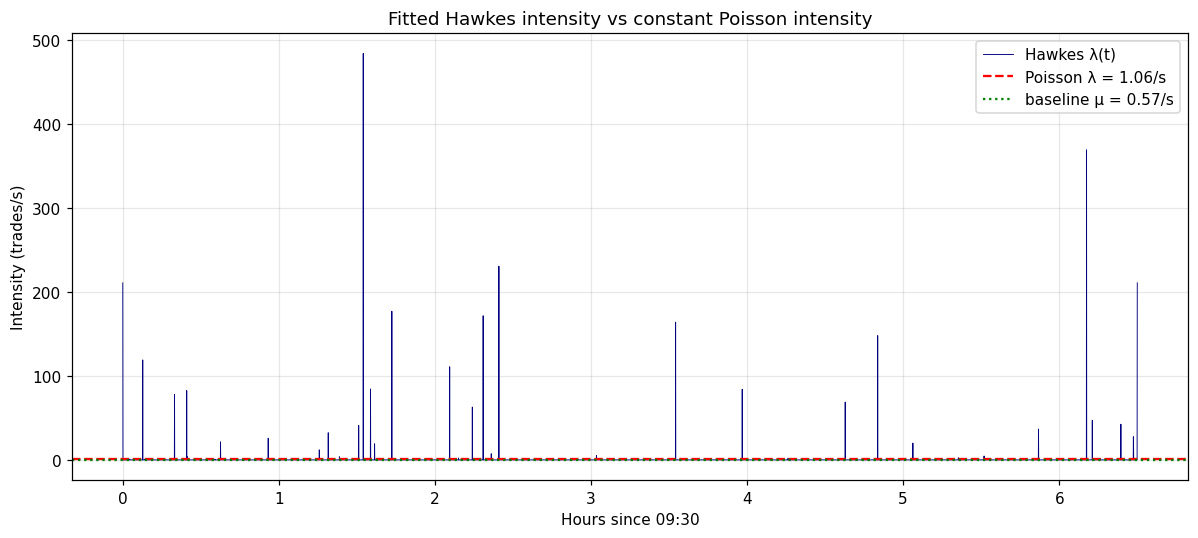

In [8]:
grid = np.linspace(0, T, 6000)
lam = intensity_on_grid(grid, t, mu, alpha, beta)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(grid/3600, lam, lw=0.6, color="navy", label="Hawkes λ(t)")
ax.axhline(pois_rate, color="red", ls="--", lw=1.5, label=f"Poisson λ = {pois_rate:.2f}/s")
ax.axhline(mu, color="green", ls=":", lw=1.5, label=f"baseline μ = {mu:.2f}/s")
ax.set(xlabel="Hours since 09:30", ylabel="Intensity (trades/s)",
       title="Fitted Hawkes intensity vs constant Poisson intensity")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(f"{PLOTS_DIR}/hawkes_intensity_full.png", dpi=130, bbox_inches="tight")
plt.show()

### 5b. Five-minute zoom — self-excitation up close

Here the mechanism is visible: each trade (tick at the bottom) makes $\lambda$ jump by $\alpha$,
which then decays at rate $\beta$. Because the fitted half-life is only a millisecond or two, the
bumps look like sharp spikes — clusters of trades ride on top of each other while quiet stretches
sit at the baseline.

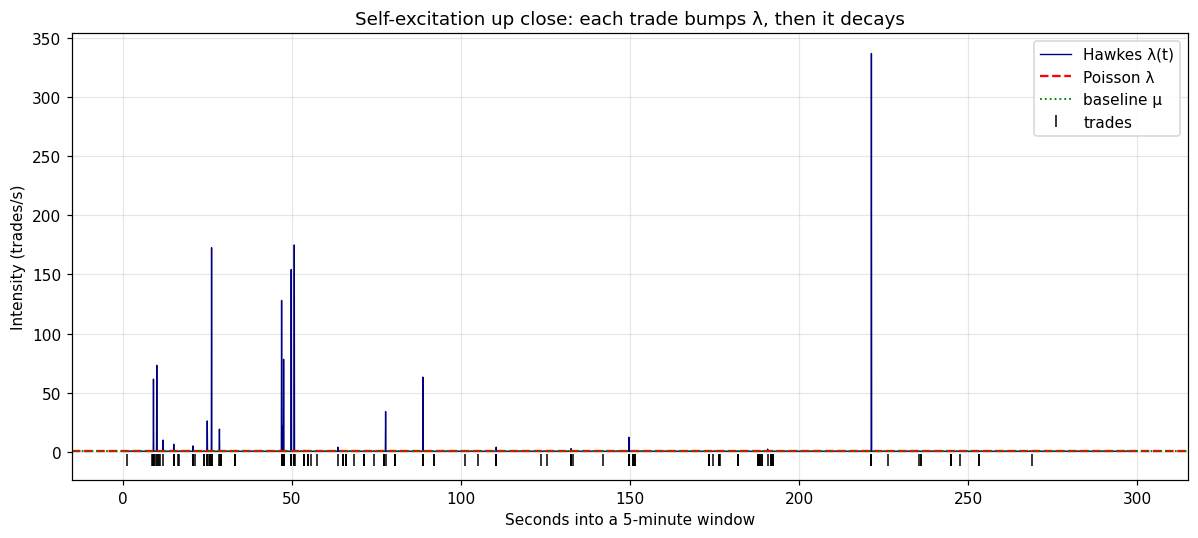

In [9]:
lo = T*0.5; hi = lo + 300.0                     # a 5-minute window
gridz = np.linspace(lo, hi, 4000)
lamz = intensity_on_grid(gridz, t, mu, alpha, beta)
evz = t[(t >= lo) & (t <= hi)]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(gridz-lo, lamz, lw=0.9, color="navy", label="Hawkes λ(t)")
ax.axhline(pois_rate, color="red", ls="--", lw=1.5, label="Poisson λ")
ax.axhline(mu, color="green", ls=":", lw=1.2, label="baseline μ")
ax.plot(evz-lo, np.full_like(evz, -0.02*lamz.max()), "|", color="black", ms=8, label="trades")
ax.set(xlabel="Seconds into a 5-minute window", ylabel="Intensity (trades/s)",
       title="Self-excitation up close: each trade bumps λ, then it decays")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(f"{PLOTS_DIR}/hawkes_intensity_zoom.png", dpi=130, bbox_inches="tight")
plt.show()

## 6. Model comparison — does Hawkes beat Poisson?

The homogeneous Poisson log-likelihood at its MLE rate $\hat\lambda=N/T$ is
$\log L_{\text{Pois}} = N\log\hat\lambda - \hat\lambda T$. Since Poisson is the **nested** special
case $\alpha=0$ of Hawkes, we can use a likelihood-ratio test (2·Δlog L $\sim \chi^2_2$) and AIC.

In [10]:
ll_hawkes = -best.fun
ll_poisson = N*np.log(pois_rate) - pois_rate*T
LR = 2*(ll_hawkes - ll_poisson)
aic_h = 2*3 - 2*ll_hawkes
aic_p = 2*1 - 2*ll_poisson
print(f"logL  Hawkes  = {ll_hawkes:,.2f}   (3 params)   AIC = {aic_h:,.2f}")
print(f"logL  Poisson = {ll_poisson:,.2f}   (1 param)    AIC = {aic_p:,.2f}")
print(f"likelihood-ratio 2*Delta = {LR:,.1f}  ->  chi^2_2 p-value = "
      f"{stats.chi2.sf(LR, 2):.3e}")
print(f"Delta AIC (Poisson - Hawkes) = {aic_p - aic_h:,.1f}  (positive favours Hawkes)")

logL  Hawkes  = 25,796.56   (3 params)   AIC = -51,587.12
logL  Poisson = -23,354.93   (1 param)    AIC = 46,711.85
likelihood-ratio 2*Delta = 98,303.0  ->  chi^2_2 p-value = 0.000e+00
Delta AIC (Poisson - Hawkes) = 98,299.0  (positive favours Hawkes)


## 7. Goodness of fit — the time-rescaling theorem

The honest test of *any* point-process model. If the model is correct, the **compensator
increments**

$$\xi_i = \Lambda(t_i) - \Lambda(t_{i-1})$$

are i.i.d. **Exponential(1)**. Intuitively, integrating real time against the fitted intensity
"stretches" busy periods and "compresses" quiet ones until what remains looks like a unit-rate
Poisson process. For the exponential kernel there is a tidy $O(N)$ closed form:

$$\xi_i = \mu\,\Delta_i + \frac{\alpha}{\beta}\big(1-e^{-\beta\Delta_i}\big)\,(1 + A_{i-1}).$$

This is the **direct sequel to Phase 1's KS test**: there we tested the *raw* interarrivals against
an exponential and rejected hard (KS ≈ 0.49). Here we test the *rescaled* increments — if Hawkes
captures the clustering, this KS statistic should be far smaller.

In [11]:
def rescaled_increments(t, mu, alpha, beta):
    A = 0.0
    xi = np.empty(t.size - 1)
    for i in range(1, t.size):
        d = t[i] - t[i-1]; ed = np.exp(-beta*d)
        xi[i-1] = mu*d + (alpha/beta)*(1.0 - ed)*(1.0 + A)
        A = ed*(1.0 + A)
    return xi

xi = rescaled_increments(t, mu, alpha, beta)
ks_stat, ks_p = stats.kstest(xi, "expon", args=(0, 1))
print(f"rescaled increments: mean={xi.mean():.3f} (Exp(1)->1.0), "
      f"var={xi.var():.3f} (Exp(1)->1.0)")
print(f"KS(xi, Exp(1)): stat={ks_stat:.4f}  p={ks_p:.3e}")
print(f"  (Phase-1 raw-interarrival KS was 0.49 — rescaling shrinks it to {ks_stat:.2f})")

rescaled increments: mean=1.000 (Exp(1)->1.0), var=2.295 (Exp(1)->1.0)
KS(xi, Exp(1)): stat=0.0911  p=7.894e-180
  (Phase-1 raw-interarrival KS was 0.49 — rescaling shrinks it to 0.09)


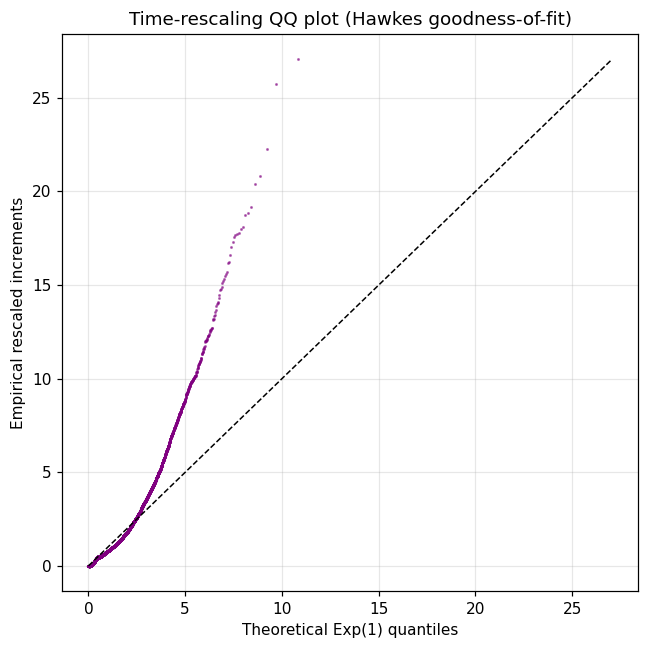

In [12]:
xs = np.sort(xi); n = xs.size
theo = -np.log(1 - (np.arange(1, n+1) - 0.5)/n)     # Exp(1) quantiles
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(theo, xs, ".", ms=2, color="purple", alpha=0.5)
hi = max(theo.max(), xs.max()); ax.plot([0, hi], [0, hi], "k--", lw=1)
ax.set(xlabel="Theoretical Exp(1) quantiles", ylabel="Empirical rescaled increments",
       title="Time-rescaling QQ plot (Hawkes goodness-of-fit)")
fig.tight_layout()
fig.savefig(f"{PLOTS_DIR}/hawkes_residual_qq.png", dpi=130, bbox_inches="tight")
plt.show()

## 8. Conclusions

| Result | Value | Reading |
|---|---|---|
| $\mu,\alpha,\beta$ | see §3 | baseline / excitation / decay |
| Branching ratio $\rho$ | $\approx 0.47$ | ~47% of trades are endogenous; **stationary** |
| Excitation half-life | $\approx 1.5$ ms | very short memory — bursts on the millisecond scale |
| $\mu/(1-\rho)$ vs $N/T$ | match | fit is self-consistent |
| LR test vs Poisson | $2\Delta \approx 10^5$, $p\ll10^{-300}$ | Poisson **decisively rejected** |
| Time-rescaling KS | $0.49 \to 0.09$ | rescaling by $\lambda(t)$ massively improves fit |

**The story across both phases.** Phase 1 *diagnosed* clustering (non-Poisson, autocorrelated,
overdispersed). Phase 2 *models* it: a Hawkes process with $\rho\approx0.47$ reproduces the
self-excitation, fits orders of magnitude better than Poisson, and — via time-rescaling — turns the
clustered trade stream into something close to unit-rate Poisson. The residual gap (KS still
formally rejected at huge $N$) is the **intraday seasonality** (the open/close U-shape) and
longer-memory effects that a single exponential kernel with constant baseline cannot absorb.

> **Next phase (not done here):** a *multivariate* buy/sell Hawkes model and/or a time-varying
> baseline $\mu(t)$, then wiring $\lambda(t)$ into the market-making quoting logic.